In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv('Student_Social_Media_And_Mental_Health_Impact.csv')

In [3]:
df.head(5)

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [4]:
df.shape

(5000, 13)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [6]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

## EDA

In [7]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [8]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [9]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

In [10]:
order = ['Low','Medium','High','Very High']

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

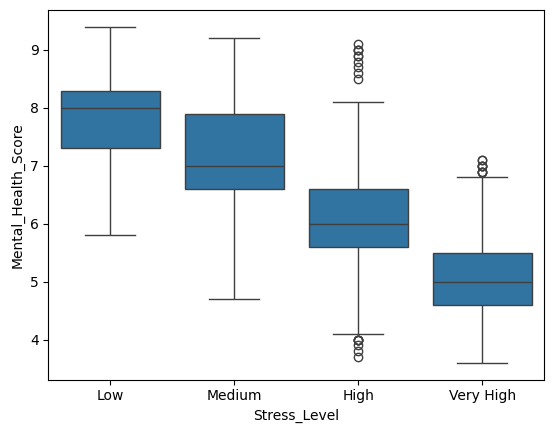

In [11]:
sns.boxplot(x = 'Stress_Level', y = 'Mental_Health_Score' , data=df , order=order)

<Axes: >

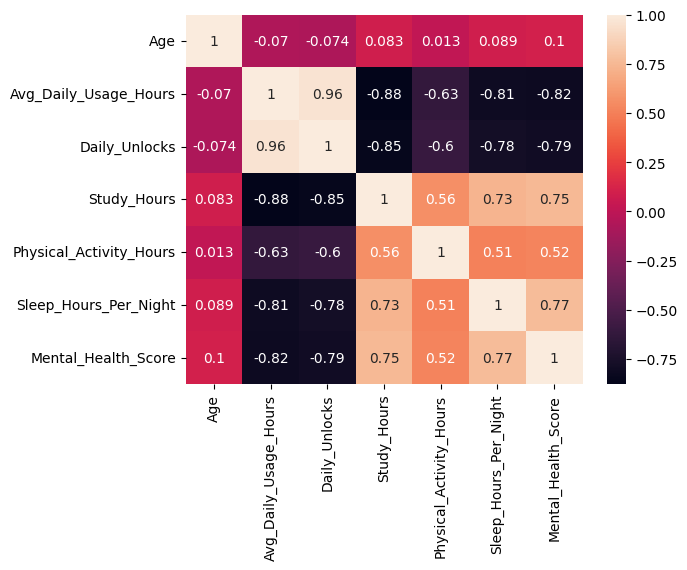

In [12]:
sns.heatmap(df.corr(numeric_only =True), annot = True)

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

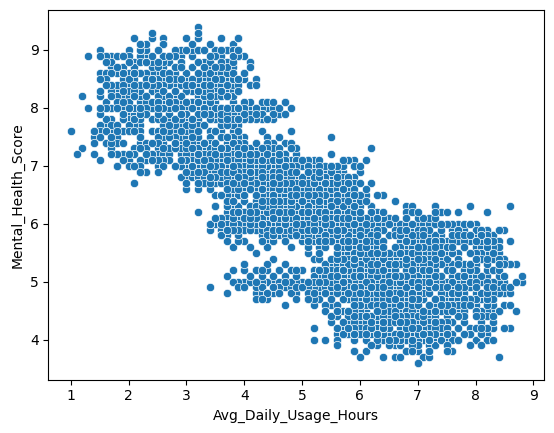

In [13]:
sns.scatterplot(x='Avg_Daily_Usage_Hours', y='Mental_Health_Score',data=df)

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

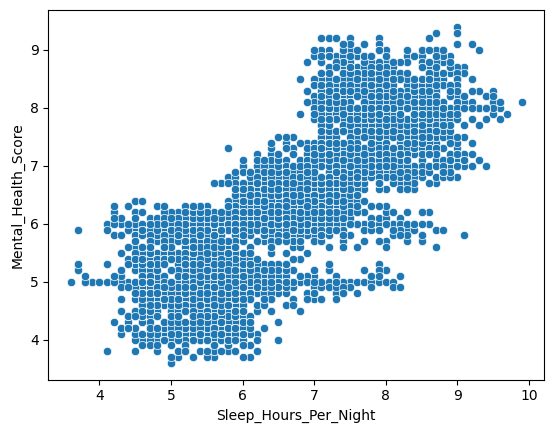

In [14]:
sns.scatterplot(x='Sleep_Hours_Per_Night', y='Mental_Health_Score',data=df)

In [15]:
platform_counts= df['Most_Used_Platform'].value_counts()
platform_counts

Most_Used_Platform
Instagram    1130
TikTok        918
Facebook      719
LinkedIn      523
YouTube       491
Twitter       462
Snapchat      420
WhatsApp      175
LINE           50
VKontakte      40
KakaoTalk      36
WeChat         36
Name: count, dtype: int64

<Axes: xlabel='Most_Used_Platform', ylabel='count'>

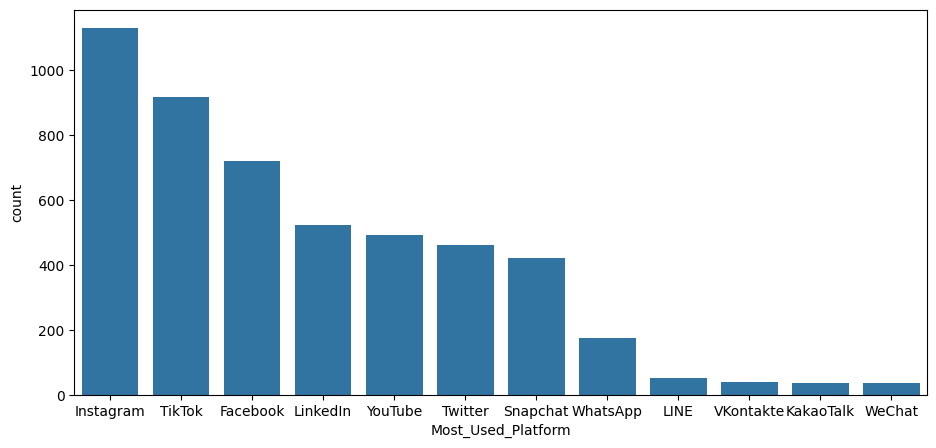

In [16]:
plt.figure(figsize=(11,5))
sns.countplot(x='Most_Used_Platform', data = df ,order = platform_counts.index)

## outliers

In [17]:
num_features = df.select_dtypes(include='number')
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3-Q1

lower_bound = Q1 - 1.5 *IQR
upper_bound = Q3 + 1.5*IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


## data cleaning

In [18]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [19]:
df.shape

(5000, 13)

In [20]:
df = df.drop_duplicates()
df.shape

(4998, 13)

In [21]:
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

In [22]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


## skewness

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

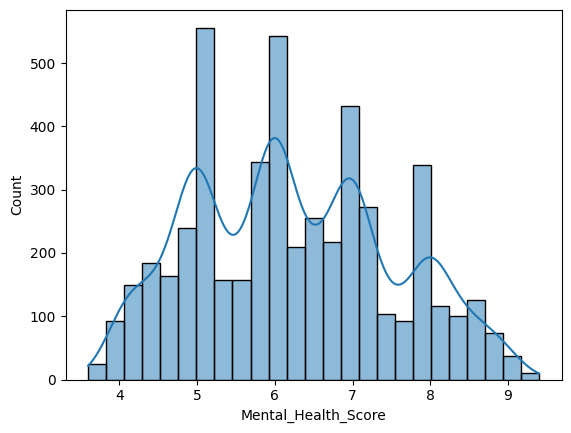

In [23]:
sns.histplot(df['Mental_Health_Score'], kde = True)

In [24]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [25]:
num_cols = df.select_dtypes(include = 'number')
num_cols.skew()

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

## feature engineering

In [26]:
top_countries = df['Country'].value_counts().index[:10].tolist()
top_countries

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France']

In [27]:
def group_countries(country):
    if country in top_countries:
        return country
    else:
        return 'Other'

In [28]:
df['grouped_country'] = df['Country'].apply(group_countries)

In [29]:
df['grouped_country'].value_counts()

grouped_country
Other        3231
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

## splitting the data 

In [30]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score', 'grouped_country'],
      dtype='object')

In [31]:
from sklearn.model_selection import train_test_split
skewed_col = ['Study_Hours']
ordinal_col = ['Stress_Level']
nominal_col = ['Gender','Academic_Level','Most_Used_Platform','Purpose_Of_Use','grouped_country']
other_numeric_cols = ['Age','Avg_Daily_Usage_Hours','Daily_Unlocks','Physical_Activity_Hours','Sleep_Hours_Per_Night']
features = (skewed_col +ordinal_col +nominal_col +other_numeric_cols)

X = df[features]
y = df['Mental_Health_Score']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [33]:
#skewed features
skew_pipeline = Pipeline(steps=[
    ('log_transform',FunctionTransformer(np.log1p)),
    ('scale',StandardScaler())
])
#numeric features
plain_numeric_pipeline = Pipeline(steps=[
    ('scale',StandardScaler())
])
#ordinal
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=[['Low','Medium','High','Very High']]))
])
#nominal
nominal_pipeline = Pipeline(steps=[
    ('encode',OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('Skewed_pipeline',skew_pipeline,skewed_col),
    ('Plain_numeric',plain_numeric_pipeline,other_numeric_cols),
    ('Ordinal',ordinal_pipeline,ordinal_col),
    ('Nominal',nominal_pipeline, nominal_col)
])

## Model Building

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

lr_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('regressor',LinearRegression())
])

lr_pipeline.fit(X_train,y_train)
lr_preds = lr_pipeline.predict(X_test)
lr_preds_train = lr_pipeline.predict(X_train)

In [35]:
lr_r2_testing = r2_score(y_test, lr_preds)
lr_r2_training = r2_score(y_train, lr_preds_train)
lr_mae = mean_absolute_error(y_test,lr_preds)

In [36]:
print(f'Accuracy of training:{lr_r2_training}')
print(f'Accuracy of testing:{lr_r2_testing}')
print(f'MAE:{lr_mae}')

Accuracy of training:0.7236771199387539
Accuracy of testing:0.7397944617433021
MAE:0.5361775634720182


## Random Forest

In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('random forest',RandomForestRegressor(random_state=42))
    
])

rf_pipeline.fit(X_train,y_train)
rf_preds = rf_pipeline.predict(X_test)
rf_preds_train = rf_pipeline.predict(X_train)

rf_r2_testing = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_train)
rf_mae = mean_absolute_error(y_test,rf_preds)

In [38]:
print(f'Accuracy of training:{rf_r2_training}')
print(f'Accuracy of testing:{rf_r2_testing}')
print(f'MAE:{rf_mae}')

Accuracy of training:0.9808287942404612
Accuracy of testing:0.8775888638668996
MAE:0.34722113333333343


## hyperparameter tuning


In [39]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    'random forest__n_estimators':[100,200,300],
    'random forest__max_depth':[5,10,15],
    'random forest__min_samples_leaf':[1,2,4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter = 15,
    cv = 5,
    scoring='r2',
    random_state=42,
    n_jobs =-1
)

random_search.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'random forest__max_depth': [5, 10, ...], 'random forest__min_samples_leaf': [1, 2, ...], 'random forest__n_estimators': [100, 200, ...]}"
,n_iter,15
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [40]:
random_search.best_params_

{'random forest__n_estimators': 100,
 'random forest__min_samples_leaf': 2,
 'random forest__max_depth': 15}

In [41]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds    = rf_best_pipeline.predict(X_test)

print(f"R2 Score for random forest after hyperparameter tuning {r2_score(y_test, rf_best_preds)}")
print(f"MAE Score for random forest after hyperparameter tuning {mean_absolute_error(y_test, rf_best_preds)}")

R2 Score for random forest after hyperparameter tuning 0.8652705553424989
MAE Score for random forest after hyperparameter tuning 0.3691015425628028


## Model evaluation

In [42]:
from sklearn.metrics import mean_squared_error

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

rf_tuned_preds          = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)


results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2': [lr_r2_training, rf_r2_training, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)

                     Model        R2  Training R2       MAE      RMSE
0        Linear Regression  0.739794     0.723677  0.536178  0.676032
1  Random Forest (default)  0.877589     0.980829  0.347221  0.463681
2    Random Forest (tuned)  0.865271     0.956394  0.369102  0.486452


## shap


In [43]:
import shap

In [44]:
rf_model = rf_pipeline.named_steps['random forest']
print(type(rf_model))

<class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [45]:
preprocessor_fitted = rf_pipeline.named_steps['preprocessor']

X_train_transformed = preprocessor_fitted.transform(X_train)
X_test_transformed = preprocessor_fitted.transform(X_test)

In [46]:
print("Training shape:", X_train_transformed.shape)
print("Testing shape:", X_test_transformed.shape)

Training shape: (3498, 38)
Testing shape: (1500, 38)


In [47]:
feature_names = []

feature_names.extend(['Study_Hours'])

feature_names.extend([
    'Age',
    'Avg_Daily_Usage_Hours',
    'Daily_Unlocks',
    'Physical_Activity_Hours',
    'Sleep_Hours_Per_Night'
])

feature_names.extend(['Stress_Level'])

onehot_encoder = preprocessor_fitted.named_transformers_['Nominal'].named_steps['encode']

nominal_features = onehot_encoder.get_feature_names_out()

feature_names.extend(nominal_features)

print("Total features:", len(feature_names))
print(feature_names)

Total features: 38
['Study_Hours', 'Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Stress_Level', 'Gender_Female', 'Gender_Male', 'Academic_Level_Graduate', 'Academic_Level_High School', 'Academic_Level_Undergraduate', 'Most_Used_Platform_Facebook', 'Most_Used_Platform_Instagram', 'Most_Used_Platform_KakaoTalk', 'Most_Used_Platform_LINE', 'Most_Used_Platform_LinkedIn', 'Most_Used_Platform_Snapchat', 'Most_Used_Platform_TikTok', 'Most_Used_Platform_Twitter', 'Most_Used_Platform_VKontakte', 'Most_Used_Platform_WeChat', 'Most_Used_Platform_WhatsApp', 'Most_Used_Platform_YouTube', 'Purpose_Of_Use_Education', 'Purpose_Of_Use_Entertainment', 'Purpose_Of_Use_Networking', 'Purpose_Of_Use_News', 'grouped_country_Australia', 'grouped_country_Canada', 'grouped_country_France', 'grouped_country_Germany', 'grouped_country_India', 'grouped_country_Mexico', 'grouped_country_Other', 'grouped_country_Turkey', 'grouped_country_UK', 'grouped_country_U

In [48]:
explainer = shap.TreeExplainer(rf_model)

In [49]:
X_test_sample = X_test_transformed[:200]

shap_values = explainer.shap_values(X_test_sample)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (200, 38)


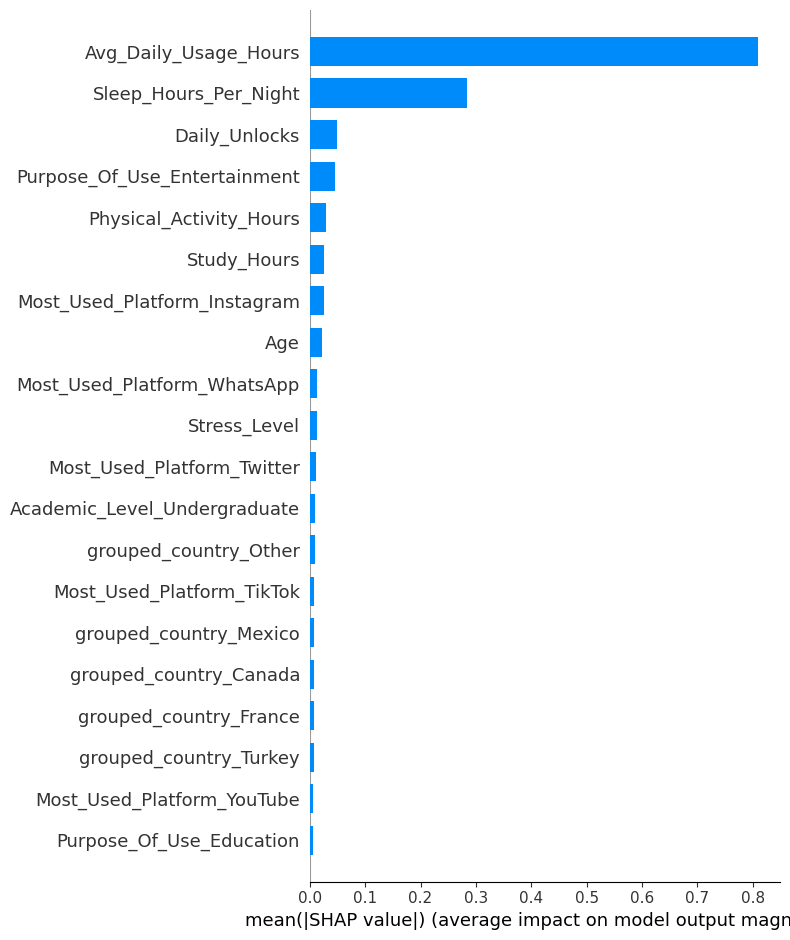

In [50]:
shap.summary_plot(
    shap_values,
    X_test_sample,
    feature_names=feature_names,
    plot_type='bar'
)

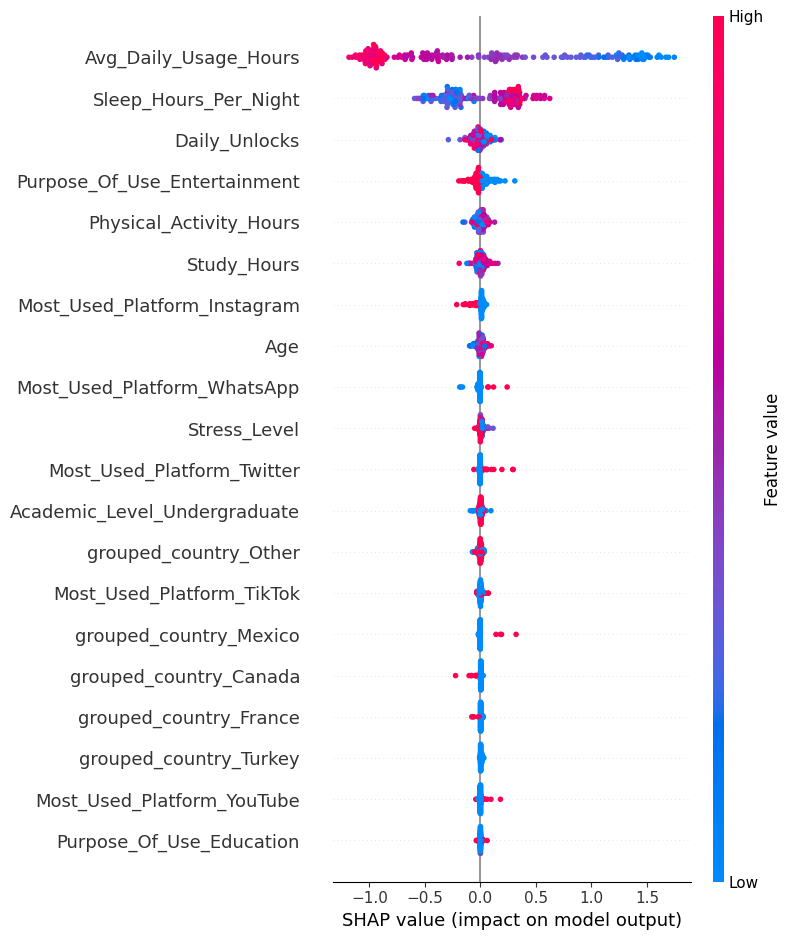

In [51]:
shap.summary_plot(
    shap_values,
    X_test_sample,
    feature_names=feature_names
)

In [52]:
student_index = 0

student_data = X_test_transformed[student_index:student_index + 1]

student_shap_values = explainer(student_data)

print("SHAP explanation generated successfully!")

SHAP explanation generated successfully!


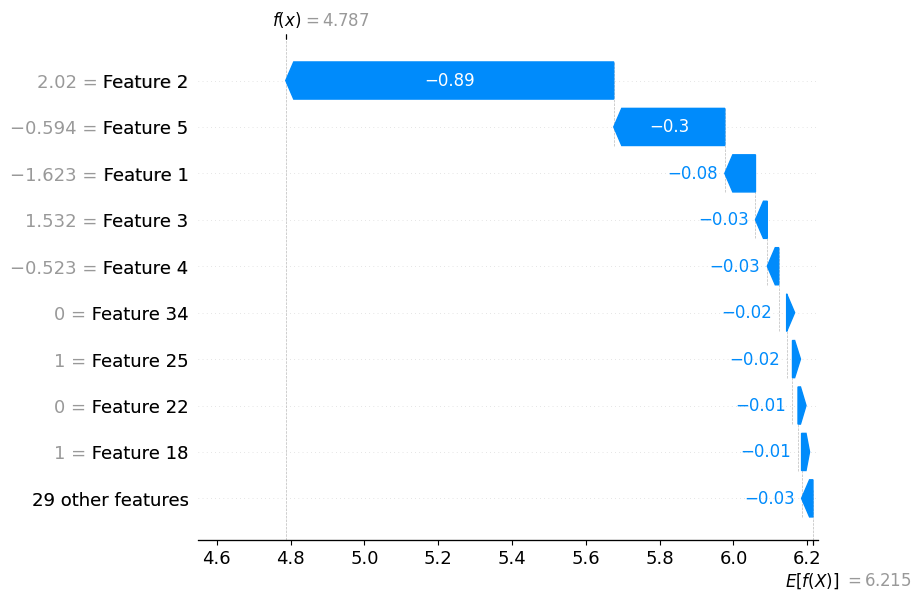

In [53]:
shap.plots.waterfall(student_shap_values[0])

In [54]:
print(feature_names)

['Study_Hours', 'Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Stress_Level', 'Gender_Female', 'Gender_Male', 'Academic_Level_Graduate', 'Academic_Level_High School', 'Academic_Level_Undergraduate', 'Most_Used_Platform_Facebook', 'Most_Used_Platform_Instagram', 'Most_Used_Platform_KakaoTalk', 'Most_Used_Platform_LINE', 'Most_Used_Platform_LinkedIn', 'Most_Used_Platform_Snapchat', 'Most_Used_Platform_TikTok', 'Most_Used_Platform_Twitter', 'Most_Used_Platform_VKontakte', 'Most_Used_Platform_WeChat', 'Most_Used_Platform_WhatsApp', 'Most_Used_Platform_YouTube', 'Purpose_Of_Use_Education', 'Purpose_Of_Use_Entertainment', 'Purpose_Of_Use_Networking', 'Purpose_Of_Use_News', 'grouped_country_Australia', 'grouped_country_Canada', 'grouped_country_France', 'grouped_country_Germany', 'grouped_country_India', 'grouped_country_Mexico', 'grouped_country_Other', 'grouped_country_Turkey', 'grouped_country_UK', 'grouped_country_USA']


In [55]:
def explain_student(student):

    student_df = pd.DataFrame([student], columns=X_train.columns)

    for col in numeric_ranges:
        student_df[col] = pd.to_numeric(student_df[col])

    student_transformed = preprocessor_fitted.transform(student_df)

    prediction = rf_pipeline.predict(student_df)[0]

    shap_explanation = explainer(student_transformed)

    contributions = shap_explanation.values[0]

    explanation_df = pd.DataFrame({
        'Feature': feature_names,
        'SHAP_Value': contributions
    })

    explanation_df['Impact'] = explanation_df['SHAP_Value'].abs()

    explanation_df = explanation_df.sort_values(
        by='Impact',
        ascending=False
    )

    positive_factors = explanation_df[
        explanation_df['SHAP_Value'] > 0
    ].head(5)

    negative_factors = explanation_df[
        explanation_df['SHAP_Value'] < 0
    ].head(5)

    return {
        'Predicted_Score': prediction,
        'Expected_Score': float(explainer.expected_value),
        'Positive_Factors': positive_factors,
        'Negative_Factors': negative_factors,
        'All_Contributions': explanation_df
    }

## NLP-Based Recommendation System


In [56]:

recommendations = [
    {
        'category': 'Sleep',
        'text': 'sleep insufficient sleep poor sleep schedule bedtime routine '
                'consistent sleeping hours improve sleep quality rest'
    },
    {
        'category': 'Stress',
        'text': 'high stress academic pressure anxiety relaxation '
                'breathing exercises meditation time management take breaks'
    },
    {
        'category': 'Social Media',
        'text': 'excessive social media screen time phone addiction '
                'reduce screen usage set app limits digital detox'
    },
    {
        'category': 'Physical Activity',
        'text': 'low physical activity sedentary lifestyle exercise '
                'walking yoga stretching physical fitness movement'
    },
    {
        'category': 'Study Habits',
        'text': 'poor study routine academic performance concentration '
                'study schedule time management productivity focus'
    },
    {
        'category': 'Healthy Lifestyle',
        'text': 'healthy lifestyle daily routine balance nutrition '
                'physical wellbeing self care healthy habits'
    },
    {
        'category': 'Mental Relaxation',
        'text': 'mental exhaustion emotional wellbeing mindfulness '
                'relaxation hobbies music spending time outdoors'
    },
    {
        'category': 'Social Support',
        'text': 'loneliness isolation emotional support friends family '
                'communication social connection talking to trusted people'
    },
    {
        'category': 'Academic Balance',
        'text': 'academic workload burnout assignments examinations '
                'balance study and personal life prioritize tasks'
    }
]

recommendation_df = pd.DataFrame(recommendations)

recommendation_df.head()


,category,text
0,Sleep,sleep insufficient sleep poor sleep schedule b...
1,Stress,high stress academic pressure anxiety relaxati...
2,Social Media,excessive social media screen time phone addic...
3,Physical Activity,low physical activity sedentary lifestyle exer...
4,Study Habits,poor study routine academic performance concen...


In [57]:
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [58]:

stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    text = text.lower()

    tokens = word_tokenize(text)

    tokens = [word for word in tokens if word not in stop_words]

    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return ' '.join(tokens)


In [59]:
recommendation_df['cleaned_text'] = recommendation_df['text'].apply(preprocess_text)

recommendation_df[['category', 'cleaned_text']].head()

,category,cleaned_text
0,Sleep,sleep insufficient sleep poor sleep schedule b...
1,Stress,high stress academic pressure anxiety relaxati...
2,Social Media,excessive social medium screen time phone addi...
3,Physical Activity,low physical activity sedentary lifestyle exer...
4,Study Habits,poor study routine academic performance concen...


In [60]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(recommendation_df['cleaned_text'])
print(tfidf_matrix.shape)

(9, 87)


In [61]:
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.head()

,academic,activity,addiction,anxiety,app,assignment,balance,bedtime,break,breathing,...,take,talking,task,time,trusted,usage,walking,wellbeing,workload,yoga
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.196244,0.000000,0.000000,...,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000
1,0.220417,0.000000,0.000000,0.300144,0.000000,0.0,0.0,0.000000,0.300144,0.300144,...,0.300144,0.0,0.0,0.194750,0.0,0.000000,0.000000,0.0,0.0,0.000000
2,0.000000,0.000000,0.248957,0.000000,0.248957,0.0,0.0,0.000000,0.000000,0.000000,...,0.000000,0.0,0.0,0.161537,0.0,0.248957,0.000000,0.0,0.0,0.000000
3,0.000000,0.285362,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,...,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.285362,0.0,0.0,0.285362
4,0.226704,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,...,0.000000,0.0,0.0,0.200306,0.0,0.000000,0.000000,0.0,0.0,0.000000


In [62]:
from sklearn.metrics.pairwise import cosine_similarity
student_query = ["high stress anxiety academic pressure"]
query_vector = tfidf.transform(student_query)
similarity_scores = cosine_similarity(query_vector, tfidf_matrix)

In [63]:
similarity_df = pd.DataFrame({
    'Category': recommendation_df['category'],
    'Similarity_Score': similarity_scores.flatten()
})

similarity_df = similarity_df.sort_values(
    by='Similarity_Score',
    ascending=False
)

similarity_df

,Category,Similarity_Score
1,Stress,0.639476
8,Academic Balance,0.080181
4,Study Habits,0.078141
0,Sleep,0.000000
2,Social Media,0.000000
3,Physical Activity,0.000000
5,Healthy Lifestyle,0.000000
6,Mental Relaxation,0.000000
7,Social Support,0.000000


In [64]:

def identify_improvement_areas(student):

    areas = []

    if student['Sleep_Hours_Per_Night'] < 7:
        areas.append('insufficient sleep poor sleep schedule bedtime routine')

    if student['Stress_Level'] in ['High', 'Very High']:
        areas.append('high stress anxiety relaxation breathing exercises')

    if student['Avg_Daily_Usage_Hours'] > 5:
        areas.append('excessive social media screen time reduce phone usage')

    if student['Physical_Activity_Hours'] < 1:
        areas.append('low physical activity exercise walking yoga')

    if student['Study_Hours'] > 8:
        areas.append('academic workload study balance time management')

    return areas


In [65]:
student = {
    'Study_Hours': 9,
    'Stress_Level': 'High',
    'Gender': 'Male',
    'Academic_Level': 'Undergraduate',
    'Most_Used_Platform': 'Instagram',
    'Purpose_Of_Use': 'Entertainment',
    'grouped_country': 'India',
    'Age': 22,
    'Avg_Daily_Usage_Hours': 7,
    'Daily_Unlocks': 100,
    'Physical_Activity_Hours': 0.5,
    'Sleep_Hours_Per_Night': 5
}

areas = identify_improvement_areas(student)

print(areas)


['insufficient sleep poor sleep schedule bedtime routine', 'high stress anxiety relaxation breathing exercises', 'excessive social media screen time reduce phone usage', 'low physical activity exercise walking yoga', 'academic workload study balance time management']


In [66]:
def get_recommendation(query):
    cleaned_query = preprocess_text(query)
    query_vector = tfidf.transform([cleaned_query])

    similarity_scores = cosine_similarity(query_vector, tfidf_matrix)

    best_match_index = similarity_scores.argmax()
    best_score = similarity_scores[0][best_match_index]

    if best_score == 0:
        return None

    return recommendation_df.iloc[best_match_index]

In [67]:
get_recommendation(
    'insufficient sleep poor sleep schedule bedtime routine'
)

category                                                    Sleep
text            sleep insufficient sleep poor sleep schedule b...
cleaned_text    sleep insufficient sleep poor sleep schedule b...
Name: 0, dtype: object

In [68]:
print(X_train.describe().T)

print("\nCategorical values:")

for col in X_train.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(X_train[col].unique())

                          count        mean        std   min    25%    50%  \
Study_Hours              3498.0    2.990852   1.628681   0.5    1.5    2.8   
Age                      3498.0   20.829617   1.744016  18.0   19.0   21.0   
Avg_Daily_Usage_Hours    3498.0    5.087707   1.640119   1.1    3.8    5.0   
Daily_Unlocks            3498.0  171.834763  42.536669  62.0  141.0  171.0   
Physical_Activity_Hours  3498.0    1.746112   0.662102   0.0    1.3    1.7   
Sleep_Hours_Per_Night    3498.0    6.625557   1.221260   3.6    5.6    6.6   

                            75%    max  
Study_Hours                4.20    8.3  
Age                       22.00   24.0  
Avg_Daily_Usage_Hours      6.30    8.8  
Daily_Unlocks            203.75  273.0  
Physical_Activity_Hours    2.20    4.1  
Sleep_Hours_Per_Night      7.50    9.9  

Categorical values:

Stress_Level:
['High' 'Very High' 'Medium' 'Low']

Gender:
['Male' 'Female']

Academic_Level:
['Graduate' 'Undergraduate' 'High School']

Most_U

In [69]:
numeric_ranges = {
    'Study_Hours': (0.5, 8.3),
    'Age': (18, 24),
    'Avg_Daily_Usage_Hours': (1.1, 8.8),
    'Daily_Unlocks': (62, 273),
    'Physical_Activity_Hours': (0, 4.1),
    'Sleep_Hours_Per_Night': (3.6, 9.9)
}

categorical_values = {
    'Stress_Level': ['Low', 'Medium', 'High', 'Very High'],
    'Gender': ['Male', 'Female'],
    'Academic_Level': ['Graduate', 'Undergraduate', 'High School'],
    'Most_Used_Platform': [
        'Facebook', 'Instagram', 'TikTok', 'LinkedIn',
        'Snapchat', 'WhatsApp', 'LINE', 'Twitter',
        'VKontakte', 'YouTube', 'WeChat', 'KakaoTalk'
    ],
    'Purpose_Of_Use': ['Networking', 'Entertainment', 'Education', 'News'],
    'grouped_country': [
        'Mexico', 'Other', 'France', 'Canada', 'USA',
        'India', 'Australia', 'UK', 'Turkey', 'Germany'
    ]
}

In [70]:
def validate_student(student):

    errors = []

    for col in X_train.columns:
        if col not in student or pd.isna(student[col]):
            errors.append(f"{col} is missing.")

    if errors:
        return errors

    for col, (min_val, max_val) in numeric_ranges.items():

        try:
            value = float(student[col])
        except (ValueError, TypeError):
            errors.append(f"{col} must be numeric.")
            continue

        if value < min_val or value > max_val:
            errors.append(
                f"{col} must be between {min_val} and {max_val}."
            )

    for col, valid_values in categorical_values.items():

        if student[col] not in valid_values:
            errors.append(
                f"{col} must be one of {valid_values}."
            )

    return errors

In [71]:
def generate_student_report(student):

    errors = validate_student(student)

    if errors:
        return {
            'status': 'error',
            'errors': errors
        }

    shap_report = explain_student(student)

    areas = identify_improvement_areas(student)

    recommendations = []

    for area in areas:

        result = get_recommendation(area)

        if result is not None:
            recommendations.append({
                'Issue': area,
                'Category': result['category'],
                'Recommendation': result['text']
            })

    return {
        'status': 'success',

        'Predicted_Mental_Health_Score':
            shap_report['Predicted_Score'],

        'Expected_Score':
            shap_report['Expected_Score'],

        'Positive_Factors':
            shap_report['Positive_Factors'],

        'Negative_Factors':
            shap_report['Negative_Factors'],

        'Improvement_Areas': areas,

        'Recommendations': recommendations
    }

In [72]:
def display_student_report(report):
    if report["status"] == "error":
        print("Invalid student information:")
        for error in report["errors"]:
            print(" -", error)
        return

    print("=" * 65)
    print("STUDENT WELLBEING ANALYSIS REPORT")
    print("=" * 65)

    score = float(report["Predicted_Mental_Health_Score"])
    expected_score = float(report["Expected_Score"])
    print(f"\nPredicted Mental Health Score: {score:.2f}")
    print(f"Expected Model Score: {expected_score:.2f}")

    print("\n" + "=" * 65)
    print("SHAP EXPLANATION")
    print("=" * 65)

    print("\nPositive Habit Contributions:")
    positive = report["Positive_Factors"]
    if positive.empty:
        print("No positive contributions found.")
    for _, row in positive.iterrows():
        print(f" - {row['Feature']}: +{row['SHAP_Value']:.3f}")

    print("\nNegative Habit Contributions:")
    negative = report["Negative_Factors"]
    if negative.empty:
        print("No negative contributions found.")
    for _, row in negative.iterrows():
        print(f" - {row['Feature']}: {row['SHAP_Value']:.3f}")

    print("\n" + "=" * 65)
    print("IMPROVEMENT AREAS")
    print("=" * 65)

    if not report["Recommendations"]:
        print("No improvement areas were flagged.")
    for i, recommendation in enumerate(report["Recommendations"], 1):
        print(f"\n{i}. {recommendation['Category']}")
        print(f"   Issue: {recommendation['Issue']}")
        print(f"   Suggestion: {recommendation['Recommendation']}")

    print("\n" + "=" * 65)


In [73]:
def display_student_report(report):

    if report['status'] == 'error':
        print("Invalid student information:")
        for error in report['errors']:
            print("-", error)
        return

    print("=" * 65)
    print("          STUDENT WELLBEING ANALYSIS REPORT")
    print("=" * 65)

    print(f"\nPredicted Mental Health Score: "
          f"{report['Predicted_Mental_Health_Score']:.2f}")

    print(f"Expected Model Score: "
          f"{report['Expected_Score']:.2f}")

    print("\n" + "=" * 65)
    print("              SHAP EXPLANATION")
    print("=" * 65)

    print("\nPositive Habit Contributions:")

    positive = report['Positive_Factors']

    if positive.empty:
        print("No positive contributions found.")

    for _, row in positive.iterrows():
        print(f"- {row['Feature']}: +{row['SHAP_Value']:.3f}")

    print("\nNegative Habit Contributions:")

    negative = report['Negative_Factors']

    if negative.empty:
        print("No negative contributions found.")

    for _, row in negative.iterrows():
        print(f"- {row['Feature']}: {row['SHAP_Value']:.3f}")

    print("\n" + "=" * 65)
    print("              IMPROVEMENT AREAS")
    print("=" * 65)

    if not report['Recommendations']:
        print("No improvement areas were flagged.")

    for i, recommendation in enumerate(report['Recommendations'], 1):
        print(f"\n{i}. {recommendation['Category']}")
        print(f"Issue: {recommendation['Issue']}")
        print(f"Suggestion: {recommendation['Recommendation']}")

    print("\n" + "=" * 65)

In [74]:
test_student = X_train.iloc[0].to_dict()

test_student.update({
    'Sleep_Hours_Per_Night': 8,
    'Stress_Level': 'Low',
    'Avg_Daily_Usage_Hours': 2,
    'Physical_Activity_Hours': 2,
    'Study_Hours': 5
})

test_report = generate_student_report(test_student)

display_student_report(test_report)

          STUDENT WELLBEING ANALYSIS REPORT

Predicted Mental Health Score: 7.68
Expected Model Score: 6.22

              SHAP EXPLANATION

Positive Habit Contributions:
- Avg_Daily_Usage_Hours: +1.287
- Sleep_Hours_Per_Night: +0.236
- Purpose_Of_Use_Entertainment: +0.034
- grouped_country_Mexico: +0.033
- Age: +0.024

Negative Habit Contributions:
- Daily_Unlocks: -0.112
- Study_Hours: -0.040
- grouped_country_Other: -0.025
- Most_Used_Platform_WhatsApp: -0.013
- Academic_Level_Graduate: -0.007

              IMPROVEMENT AREAS
No improvement areas were flagged.



In [75]:
errors = validate_student(test_student)

print(errors)

[]


In [76]:
invalid_student = test_student.copy()

invalid_student['Age'] = 150
invalid_student['Stress_Level'] = 'Unknown'

print(validate_student(invalid_student))

['Age must be between 18 and 24.', "Stress_Level must be one of ['Low', 'Medium', 'High', 'Very High']."]


In [77]:
report = generate_student_report(test_student)

print(report)

{'status': 'success', 'Predicted_Mental_Health_Score': np.float64(7.681000000000001), 'Expected_Score': 6.215335620354488, 'Positive_Factors':                          Feature  SHAP_Value    Impact
2          Avg_Daily_Usage_Hours    1.287345  1.287345
5          Sleep_Hours_Per_Night    0.236144  0.236144
25  Purpose_Of_Use_Entertainment    0.034479  0.034479
33        grouped_country_Mexico    0.033300  0.033300
1                            Age    0.024197  0.024197, 'Negative_Factors':                         Feature  SHAP_Value    Impact
3                 Daily_Unlocks   -0.112377  0.112377
0                   Study_Hours   -0.039525  0.039525
34        grouped_country_Other   -0.024825  0.024825
22  Most_Used_Platform_WhatsApp   -0.013175  0.013175
9       Academic_Level_Graduate   -0.006820  0.006820, 'Improvement_Areas': [], 'Recommendations': []}


In [78]:
report = generate_student_report(invalid_student)

print(report)

{'status': 'error', 'errors': ['Age must be between 18 and 24.', "Stress_Level must be one of ['Low', 'Medium', 'High', 'Very High']."]}


In [79]:
import joblib
import os

os.makedirs('models', exist_ok=True)

joblib.dump(rf_best_pipeline, 'models/ml_model.pkl')
joblib.dump(tfidf, 'models/tfidf_vectorizer.pkl')
joblib.dump(recommendation_df, 'models/recommendations.pkl')

print("All models saved successfully!")

All models saved successfully!


In [80]:
student_explanation = explain_student(test_student)

print("Predicted Score:",
      student_explanation['Predicted_Score'])

print("\nPositive Habit Contributions:")
display(student_explanation['Positive_Factors'])

print("\nNegative Habit Contributions:")
display(student_explanation['Negative_Factors'])

Predicted Score: 7.681000000000001

Positive Habit Contributions:


,Feature,SHAP_Value,Impact
2,Avg_Daily_Usage_Hours,1.287345,1.287345
5,Sleep_Hours_Per_Night,0.236144,0.236144
25,Purpose_Of_Use_Entertainment,0.034479,0.034479
33,grouped_country_Mexico,0.033300,0.033300
1,Age,0.024197,0.024197



Negative Habit Contributions:


,Feature,SHAP_Value,Impact
3,Daily_Unlocks,-0.112377,0.112377
0,Study_Hours,-0.039525,0.039525
34,grouped_country_Other,-0.024825,0.024825
22,Most_Used_Platform_WhatsApp,-0.013175,0.013175
9,Academic_Level_Graduate,-0.006820,0.006820
